# 09 — Step 5: Compound-handling methods (M1 / M2 / M3) vs baseline

**Proshno (RQ2):** compound split kore retrieval korle ki baseline-er cheye valo hoy? Kon density bin-e kon method jite?

| Method | Ki kore | Kon leg-e |
|---|---|---|
| **M1** decompounded BM25 | query + document-e compound **ebong** tar parts duita-i index (`etanolbilarna etanol bilarna`) | BM25 |
| **M1-CPf** M1, kintu CompoundPiece-er split **filter kore** (shob part real, frequent shobd hole-i accept) | BM25 |
| **M2** char n-gram BM25 | 3–5 akshor-er tukro diye BM25, splitter lage na | BM25 |
| **M3** query expansion | Dense query-te parts jure dey (`etanolbilarna (etanol bilarna)`) | Dense |
| **Hybrid variants** | compound-aware BM25 leg + Dense (RRF) | Hybrid |

M1 dui splitter diye: **CP** (CompoundPiece) ar **KK** (Koehn & Knight). Kon ta valo seta 08-er manual validation + ei result-er upor decide hobe.

**Dev/test (Step 2):** ekhane kono hyperparameter tune kori nai (shob default), tai shob query-te report kori, sathe Swedn **test_** subset-o alada. Tuning Step 6-e (train_/validation_ diye) hobe.

**Kaggle setup:** GPU On, Internet On. **Add Input**-e duita: `07_hybrid_fixed` (embedding `.npy`) ar `08_compound_density` (`cp_cache.json`, `sv_freq.json`, `compound_density_per_query.csv`). Repo-te `src/sparse.py` push kora lagbe.

In [4]:
!pip install datasets rank_bm25 statsmodels sentence-transformers -q

In [5]:
import os, sys, subprocess, glob, json, shutil, time
REPO_URL = "https://github.com/medhuuuu/swedish-retrieval-project.git"
REPO_DIR = "/kaggle/working/swedish-retrieval-project"
if os.path.exists(REPO_DIR):
    print(subprocess.run(["git", "-C", REPO_DIR, "pull"], capture_output=True, text=True).stdout)
else:
    print(subprocess.run(["git", "clone", REPO_URL, REPO_DIR], capture_output=True, text=True).stderr)
os.chdir(REPO_DIR)
if REPO_DIR not in sys.path: sys.path.insert(0, REPO_DIR)

BASE = "/kaggle/working/swedish_retrieval"
CACHE_DIR = os.path.join(BASE, "cache"); os.makedirs(CACHE_DIR, exist_ok=True)
RES_DIR = os.path.join(REPO_DIR, "results"); os.makedirs(RES_DIR, exist_ok=True)

def find_file(name):
    for p in glob.glob(f"/kaggle/input/**/{name}", recursive=True) + [os.path.join(RES_DIR, name), os.path.join(CACHE_DIR, name)]:
        if os.path.exists(p): return p
    return None

# ager notebook-er cache restore (embedding .npy, CompoundPiece cache, frequency list)
for f in glob.glob("/kaggle/input/**/*.npy", recursive=True) + [find_file("cp_cache.json"), find_file("sv_freq.json")]:
    if f and not os.path.exists(os.path.join(CACHE_DIR, os.path.basename(f))):
        shutil.copy(f, os.path.join(CACHE_DIR, os.path.basename(f))); print("restored", os.path.basename(f))

PERQ = find_file("baselines_v2_perquery.jsonl"); QDENS = find_file("compound_density_per_query.csv")
print("perquery:", PERQ, "\ndensity :", QDENS)
assert PERQ and QDENS, "07 ar 08 notebook-er output Add Input koro"

from src.compound import CompoundSplitter, CompoundPieceSplitter, load_freq
from src.sparse import SparseBM25, FilteredSplitter, tokenize, decompound_tokens, char_ngrams, expand_query_inline
from src.utils import load_swefaq, load_swedn, build_qrels_dict, build_chunked_corpus, reciprocal_rank_fusion, recall_at_k, ndcg_at_k
import numpy as np, pandas as pd

Already up to date.

perquery: /kaggle/input/notebooks/tanjilaahmed/07-hybrid-fixed/swedish-retrieval-project/results/baselines_v2_perquery.jsonl 
density : /kaggle/input/notebooks/tanjilaahmed/08-compound-density/swedish-retrieval-project/results/compound_density_per_query.csv


In [6]:
swefaq_corpus, swefaq_queries, swefaq_qrels = load_swefaq()
swedn_corpus, swedn_queries, swedn_qrels = load_swedn()
DS = ["swefaq", "swedn"]
qrels = {"swefaq": build_qrels_dict(swefaq_qrels), "swedn": build_qrels_dict(swedn_qrels)}
corp = {"swefaq": ([d["_id"] for d in swefaq_corpus], [d["text"] for d in swefaq_corpus]),
        "swedn":  ([d["_id"] for d in swedn_corpus],  [d["text"] for d in swedn_corpus])}
queries = {"swefaq": [(q["_id"], q["text"]) for q in swefaq_queries if q["_id"] in qrels["swefaq"]],
           "swedn":  [(q["_id"], q["text"]) for q in swedn_queries  if q["_id"] in qrels["swedn"]]}
print({ds: (len(corp[ds][0]), len(queries[ds])) for ds in DS})

{'swefaq': (511, 513), 'swedn': (6141, 3072)}


## 1. Splitters (CompoundPiece + Koehn & Knight)
CompoundPiece-ke ekhon **shob document-er** shobde chalate hobe (M1-e shob doc index hoy). 08-e shudhu relevant doc-er shobd hoyechilo, baki notun shobd ~10–20 minute lagte pare (GPU). Ekbar hole `cp_cache.json`-e save thake.

In [7]:
FREQ_PATH = os.path.join(CACHE_DIR, "sv_freq.json"); CP_CACHE = os.path.join(CACHE_DIR, "cp_cache.json")
assert os.path.exists(FREQ_PATH), "sv_freq.json nai: 08-er output Add Input koro"
kk = CompoundSplitter(load_freq(FREQ_PATH), min_part_len=3, min_part_freq=30, min_word_len=7, max_parts=3)
cp = CompoundPieceSplitter(cache_path=CP_CACHE, min_word_len=7)

all_words = set()
for ds in DS:
    for t in corp[ds][1]: all_words.update(w for w in tokenize(t) if w.isalpha())
    for _, t in queries[ds]: all_words.update(w for w in tokenize(t) if w.isalpha())
print("unique alphabetic words:", len(all_words), "| len>=7:", sum(len(w) >= 7 for w in all_words))
t0 = time.time(); cp.precompute(all_words); print("CompoundPiece done:", round(time.time() - t0), "s")
for w in ["etanolbilarna", "museiavgifterna", "sömmerskebrist", "rundgång"]:
    print(f"{w:18s} CP={cp.split(w)}  KK={kk.split(w)}")

unique alphabetic words: 118291 | len>=7: 95030
CompoundPiece: 133 new words (94940 cached)


config.json:   0%|          | 0.00/792 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.50k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/3.09k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.33GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.33GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

CompoundPiece done: 33 s
etanolbilarna      CP=['etanol', 'bilarna']  KK=['etanol', 'bil', 'rna']
museiavgifterna    CP=['museum', 'avgifterna']  KK=['musei', 'avgift', 'rna']
sömmerskebrist     CP=['sömmerska', 'brist']  KK=['sömmerskebrist']
rundgång           CP=['rund', 'gång']  KK=['rund', 'gång']


### Precision filter (M1-CPf)
Duto splitter-i prai ordhek split bhul kore (`lära rna`, `etan len`). Filter: split tokhoni accept, jokhon **shob part** real shobd (length >= 3, corpus frequency >= threshold). Threshold ta tomar 150-shobder label diye choose hoy (F1 shobcheye beshi je threshold-e). Label file na pele default 1000.

In [8]:
from src.sparse import FilteredSplitter
lab_path = find_file("compound_validation_labeled.csv")
FILT_FREQ = 1000
if lab_path:
    lab = pd.read_csv(lab_path, dtype=str).fillna(""); lab = lab[lab.true_compound.isin(["0", "1"])]
    gold = (lab.true_compound == "1").values
    sweep = []
    for mf in [0, 100, 300, 1000, 3000, 10000, 30000]:
        f = FilteredSplitter(cp, kk.freq, 3, mf); pred = np.array([f.is_compound(w) for w in lab.word])
        tp = (pred & gold).sum(); P = tp / max(pred.sum(), 1); Rr = tp / gold.sum()
        sweep.append({"min_part_freq": mf, "splits": int(pred.sum()), "detect P": P, "detect R": Rr, "F1": 2 * P * Rr / max(P + Rr, 1e-9)})
    sweep = pd.DataFrame(sweep); print(sweep.round(3).to_string(index=False))
    FILT_FREQ = int(sweep.sort_values(["F1", "min_part_freq"]).iloc[-1].min_part_freq)
    print("chosen min_part_freq =", FILT_FREQ, "(150-sample-e F1 max)")
cpf = FilteredSplitter(cp, kk.freq, 3, FILT_FREQ)
for w in ["lärarna", "etanolen", "snabbast", "rundgång", "etanolbilarna", "kameraövervakning", "barnbidrag"]:
    print(f"{w:20s} CP={cp.split(w)}  CPf={cpf.split(w)}")

lärarna              CP=['lärarna']  CPf=['lärarna']
etanolen             CP=['etanolen']  CPf=['etanolen']
snabbast             CP=['snabb', 'ast']  CPf=['snabbast']
rundgång             CP=['rund', 'gång']  CPf=['rundgång']
etanolbilarna        CP=['etanol', 'bilarna']  CPf=['etanolbilarna']
kameraövervakning    CP=['kamera', 'övervakning']  CPf=['kameraövervakning']
barnbidrag           CP=['barn', 'bidrag']  CPf=['barn', 'bidrag']


## 2. Dense embeddings (e5-base, cache restore) + vectorised dense search

In [9]:
import torch
from sentence_transformers import SentenceTransformer
emb_model = SentenceTransformer("intfloat/multilingual-e5-base", device="cuda:0" if torch.cuda.is_available() else "cpu")
emb_model.max_seq_length = 512

def cached_encode(name, texts):
    path = os.path.join(CACHE_DIR, f"{name}.npy")
    if os.path.exists(path):
        arr = np.load(path)
        if len(arr) == len(texts): print(f"[cache hit] {name} {arr.shape}"); return arr
    arr = emb_model.encode(["passage: " + t for t in texts], batch_size=64, show_progress_bar=True, normalize_embeddings=True)
    np.save(path, arr); return arr

swefaq_emb = cached_encode("swefaq_passages", corp["swefaq"][1])
chunk_ids, chunk_texts, parent_ids = build_chunked_corpus(swedn_corpus)
swedn_chunk_emb = cached_encode("swedn_chunks_400_50", chunk_texts)

parent_arr = np.array(parent_ids)
starts = np.flatnonzero(np.r_[True, parent_arr[1:] != parent_arr[:-1]])       # chunks contiguous per parent
assert [parent_ids[i] for i in starts] == corp["swedn"][0], "chunk-parent order corpus order-er shathe mile na"

def dense_rank(ds, qtexts, k=100):
    # utils.dense_ranked_ids_chunked-er moto (max-pool chunk), kintu shob query ek shathe
    Q = emb_model.encode(["query: " + q for q in qtexts], batch_size=64, normalize_embeddings=True)
    if ds == "swefaq": S = Q @ swefaq_emb.T
    else: S = np.maximum.reduceat(Q @ swedn_chunk_emb.T, starts, axis=1)
    ids = corp[ds][0]; out = []
    for row in S:
        top = np.argpartition(-row, k - 1)[:k]; top = top[np.argsort(-row[top], kind="stable")]
        out.append([ids[i] for i in top])
    return out

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

[cache hit] swefaq_passages (511, 768)
[cache hit] swedn_chunks_400_50 (10136, 768)


## 3. Shob method-er top-100 ranking
Sparse: `BM25` (ager moto, own sparse implementation, sanity check niche), `M1-CP`, `M1-KK`, `M2-ngram`.
Dense: `Dense` (baseline), `M3-CP`, `M3-KK` (query-te parts jora).
Hybrid: RRF (k=60, pool 100) — baseline ar compound-aware variants.

In [10]:
R = {}                       # R[(ds, method)] = {qid: top-100 ids}
info = []                    # index size / time
ANALYZERS = {"BM25": tokenize,
             "M1-CP": lambda t: decompound_tokens(t, cp),
             "M1-KK": lambda t: decompound_tokens(t, kk),
             "M1-CPf": lambda t: decompound_tokens(t, cpf),
             "M2-ngram": lambda t: char_ngrams(t, (3, 4, 5))}
for ds in DS:
    ids, texts = corp[ds]; qids = [q for q, _ in queries[ds]]; qtexts = [t for _, t in queries[ds]]
    for name, an in ANALYZERS.items():
        t0 = time.time(); idx = SparseBM25([an(t) for t in texts]); t_idx = time.time() - t0
        t0 = time.time(); R[(ds, name)] = {q: idx.top_ids(an(t), ids, 100) for q, t in zip(qids, qtexts)}
        info.append({"ds": ds, "method": name, "vocab": len(idx.vocab), "nnz (M)": round(idx.W.nnz / 1e6, 2),
                     "index_s": round(t_idx, 1), "ms/query": round(1000 * (time.time() - t0) / len(qids), 2)})
        print(ds, name, "done", round(t_idx), "s")
    R[(ds, "Dense")]  = dict(zip(qids, dense_rank(ds, qtexts)))
    R[(ds, "M3-CP")]  = dict(zip(qids, dense_rank(ds, [expand_query_inline(t, cp) for t in qtexts])))
    R[(ds, "M3-KK")]  = dict(zip(qids, dense_rank(ds, [expand_query_inline(t, kk) for t in qtexts])))
    for hname, (a, b) in {"Hybrid": ("BM25", "Dense"), "Hyb(M1-CP+Dense)": ("M1-CP", "Dense"),
                          "Hyb(M1-KK+Dense)": ("M1-KK", "Dense"), "Hyb(M1-CPf+Dense)": ("M1-CPf", "Dense"), "Hyb(M2+Dense)": ("M2-ngram", "Dense"),
                          "Hyb(BM25+M3-CP)": ("BM25", "M3-CP"), "Hyb(M1-CP+M3-CP)": ("M1-CP", "M3-CP"),
                          "Hyb(M2+M3-CP)": ("M2-ngram", "M3-CP")}.items():
        R[(ds, hname)] = {q: reciprocal_rank_fusion(R[(ds, a)][q], R[(ds, b)][q])[:100] for q in qids}
pd.DataFrame(info)

swefaq BM25 done 0 s
swefaq M1-CP done 0 s
swefaq M1-KK done 0 s
swefaq M1-CPf done 0 s
swefaq M2-ngram done 0 s
swedn BM25 done 2 s
swedn M1-CP done 3 s
swedn M1-KK done 4 s
swedn M1-CPf done 4 s
swedn M2-ngram done 18 s


,ds,method,vocab,nnz (M),index_s,ms/query
0,swefaq,BM25,3426,0.02,0.0,0.19
1,swefaq,M1-CP,4071,0.02,0.0,0.20
2,swefaq,M1-KK,4135,0.02,0.1,0.20
3,swefaq,M1-CPf,3544,0.02,0.0,0.20
4,swefaq,M2-ngram,20766,0.21,0.2,0.36
5,swedn,BM25,118176,1.10,1.8,0.21
6,swedn,M1-CP,127936,1.36,3.0,0.24
7,swedn,M1-KK,121204,1.43,4.5,0.26
8,swedn,M1-CPf,118185,1.18,3.5,0.24
9,swedn,M2-ngram,259724,11.85,17.7,0.61


## 4. Evaluate (per-query save)

In [11]:
METHODS = ["BM25", "M1-CP", "M1-CPf", "M1-KK", "M2-ngram", "Dense", "M3-CP", "M3-KK", "Hybrid",
           "Hyb(M1-CP+Dense)", "Hyb(M1-CPf+Dense)", "Hyb(M1-KK+Dense)", "Hyb(M2+Dense)", "Hyb(BM25+M3-CP)", "Hyb(M1-CP+M3-CP)", "Hyb(M2+M3-CP)"]
rows = []
for ds in DS:
    for m in METHODS:
        for qid, _ in queries[ds]:
            ranked, rel = R[(ds, m)][qid], qrels[ds][qid]
            rows.append({"ds": ds, "method": m, "qid": qid, "r1": recall_at_k(ranked, rel, 1), "r3": recall_at_k(ranked, rel, 3),
                         "r10": recall_at_k(ranked, rel, 10), "ndcg10": ndcg_at_k(ranked, rel, 10)})
res = pd.DataFrame(rows)
res.to_json(os.path.join(RES_DIR, "step5_perquery.jsonl"), orient="records", lines=True)

# sanity: BM25 / Dense / Hybrid ager v2 baseline-er shathe mile kina
v2 = pd.read_json(PERQ, lines=True).groupby("exp").ndcg10.mean()
chk = pd.DataFrame({"now": [res[(res.ds == d) & (res.method == m)].ndcg10.mean() for d, m in
                            [("swefaq","BM25"),("swefaq","Dense"),("swefaq","Hybrid"),("swedn","BM25"),("swedn","Dense"),("swedn","Hybrid")]],
                    "v2 (07)": [v2["swefaq_bm25"], v2["swefaq_dense"], v2["swefaq_hybrid"], v2["swedn_bm25"], v2["swedn_dense_chunked"], v2["swedn_hybrid_chunked"]]},
                   index=["swefaq BM25", "swefaq Dense", "swefaq Hybrid", "swedn BM25", "swedn Dense(chunked)", "swedn Hybrid(chunked)"]).round(4)
print("SANITY (duita column prai soman hote hobe):"); chk

SANITY (duita column prai soman hote hobe):


,now,v2 (07)
swefaq BM25,0.5216,0.5216
swefaq Dense,0.7528,0.7528
swefaq Hybrid,0.6718,0.6725
swedn BM25,0.6803,0.6803
swedn Dense(chunked),0.7769,0.7769
swedn Hybrid(chunked),0.7576,0.7573


### Overall result (nDCG@10, Recall@1, Recall@10)

In [12]:
res["split"] = np.where((res.ds == "swedn") & res.qid.str.startswith("test_"), "swedn(test_)", res.ds)
def table(metric):
    a = res.pivot_table(index="method", columns="ds", values=metric)
    b = res[res.split == "swedn(test_)"].pivot_table(index="method", columns="split", values=metric)
    return a.join(b).reindex(METHODS)[["swefaq", "swedn", "swedn(test_)"]]
overall = table("ndcg10").round(4); overall.to_csv(os.path.join(RES_DIR, "step5_overall_ndcg10.csv"))
print("nDCG@10"); display(overall)
print("Recall@1"); display(table("r1").round(4)); print("Recall@10"); display(table("r10").round(4))

nDCG@10


,swefaq,swedn,swedn(test_)
method,,,
BM25,0.5216,0.6803,0.6474
M1-CP,0.5846,0.7203,0.6790
M1-CPf,0.5365,0.6856,0.6493
M1-KK,0.5712,0.7154,0.6756
M2-ngram,0.6422,0.7563,0.7127
Dense,0.7528,0.7769,0.7379
M3-CP,0.7469,0.7457,0.7162
M3-KK,0.7404,0.7312,0.6997
Hybrid,0.6718,0.7576,0.7211


Recall@1


,swefaq,swedn,swedn(test_)
method,,,
BM25,0.3450,0.3576,0.3486
M1-CP,0.4308,0.3734,0.3584
M1-CPf,0.3606,0.3574,0.3457
M1-KK,0.4016,0.3727,0.3579
M2-ngram,0.4873,0.3968,0.3809
Dense,0.6062,0.3840,0.3594
M3-CP,0.5984,0.3716,0.3516
M3-KK,0.5867,0.3586,0.3350
Hybrid,0.5205,0.3895,0.3779


Recall@10


,swefaq,swedn,swedn(test_)
method,,,
BM25,0.7115,0.7174,0.6831
M1-CP,0.7505,0.7637,0.7212
M1-CPf,0.7193,0.7271,0.6914
M1-KK,0.7505,0.7609,0.7222
M2-ngram,0.8051,0.7931,0.7495
Dense,0.9025,0.8286,0.8130
M3-CP,0.8986,0.7985,0.7881
M3-KK,0.8928,0.7902,0.7793
Hybrid,0.8207,0.8044,0.7676


## 5. Compound density bin onujayi (RQ2-r core)
08-er `compound_density_per_query.csv` (CompoundPiece density) use kori. Bin: none / low / high (dataset-er positive median).

In [13]:
qd = pd.read_csv(QDENS)
def make_bins(df, col):
    pos = df[col][df[col] > 0]; med = pos.median() if len(pos) else 0
    return np.where(df[col] == 0, "0_none", np.where(df[col] <= med, "1_low", "2_high"))
for ds in DS:
    m = qd.ds == ds; qd.loc[m, "q_bin"] = make_bins(qd[m], "q_dens")
long = res.merge(qd[["ds", "qid", "q_len", "q_dens", "q_bin"]], on=["ds", "qid"], how="inner")

rng = np.random.default_rng(0)
def boot_ci(x, n=2000):
    x = np.asarray(x, float); idx = rng.integers(0, len(x), (n, len(x))); m = x[idx].mean(1)
    return tuple(np.percentile(m, [2.5, 97.5]))
MAIN = ["BM25", "M1-CP", "M1-CPf", "M1-KK", "M2-ngram", "Dense", "M3-CP", "M3-KK", "Hybrid", "Hyb(M1-CP+Dense)", "Hyb(M1-CPf+Dense)", "Hyb(M2+Dense)", "Hyb(M1-CP+M3-CP)"]
bt = long[long.method.isin(MAIN)].pivot_table(index=["ds", "q_bin"], columns="method", values="ndcg10")[MAIN]
bt["n"] = long[long.method == "BM25"].groupby(["ds", "q_bin"]).size()
bt.round(3).to_csv(os.path.join(RES_DIR, "step5_bins_ndcg10.csv")); bt.round(3)

method          BM25  M1-CP  M1-CPf  M1-KK  M2-ngram  Dense  M3-CP  M3-KK  \
ds     q_bin                                                                
swedn  0_none  0.661  0.669   0.663  0.663     0.696  0.720  0.720  0.692   
       1_low   0.735  0.763   0.738  0.763     0.800  0.829  0.798  0.785   
       2_high  0.641  0.730   0.654  0.721     0.775  0.783  0.717  0.715   
swefaq 0_none  0.496  0.502   0.497  0.507     0.608  0.755  0.755  0.745   
       1_low   0.518  0.569   0.533  0.578     0.615  0.730  0.715  0.715   
       2_high  0.546  0.664   0.571  0.614     0.696  0.774  0.774  0.763   

method         Hybrid  Hyb(M1-CP+Dense)  Hyb(M1-CPf+Dense)  Hyb(M2+Dense)  \
ds     q_bin                                                                
swedn  0_none   0.717             0.727              0.722          0.737   
       1_low    0.813             0.830              0.816          0.841   
       2_high   0.741             0.792              0.753          0.807   
swefaq 0_none   0.656             0.681              0.671          0.725   
       1_low    0.652             0.650              0.650          0.700   
       2_high   0.704             0.749              0.717          0.755   

method         Hyb(M1-CP+M3-CP)     n  
ds     q_bin                           
swedn  0_none             0.727  1050  
       1_low              0.822  1052  
       2_high             0.774   970  
swefaq 0_none             0.681   141  
       1_low              0.664   189  
       2_high             0.756   183

### Paired differences (method − baseline) per bin, 95% bootstrap CI

In [14]:
PAIRS = [("M1-CP", "BM25"), ("M1-CPf", "BM25"), ("M1-KK", "BM25"), ("M2-ngram", "BM25"), ("M3-CP", "Dense"), ("M3-KK", "Dense"),
         ("Hyb(M1-CP+Dense)", "Hybrid"), ("Hyb(M1-CPf+Dense)", "Hybrid"), ("Hyb(M2+Dense)", "Hybrid"), ("Hyb(M1-CP+M3-CP)", "Hybrid"),
         ("Hyb(M1-CP+Dense)", "Dense"), ("Hyb(M1-CPf+Dense)", "Dense"), ("Hyb(M2+Dense)", "Dense"), ("Hyb(M1-CP+M3-CP)", "Dense")]
wide = long.pivot_table(index=["ds", "qid", "q_bin", "q_len"], columns="method", values="ndcg10").reset_index()
out = []
for ds in DS:
    w = wide[wide.ds == ds]
    for a, b in PAIRS:
        for qb, g in [("ALL", w)] + list(w.groupby("q_bin")):
            d = (g[a] - g[b]).values; lo, hi = boot_ci(d)
            out.append({"ds": ds, "A - B": f"{a} - {b}", "bin": qb, "n": len(d), "mean_diff": d.mean(), "ci_lo": lo, "ci_hi": hi, "sig (CI excl. 0)": (lo > 0) or (hi < 0)})
diff = pd.DataFrame(out); diff.round(3).to_csv(os.path.join(RES_DIR, "step5_paired_diff_by_bin.csv"), index=False)
for ds in DS:
    print("=====", ds); display(diff[diff.ds == ds].pivot_table(index="A - B", columns="bin", values="mean_diff", sort=False).round(3))
print("Significant (CI excludes 0) rows:"); display(diff[diff["sig (CI excl. 0)"]].round(3).drop(columns="sig (CI excl. 0)").head(60))

===== swefaq


bin,ALL,0_none,1_low,2_high
A - B,,,,
M1-CP - BM25,0.063,0.006,0.051,0.119
M1-CPf - BM25,0.015,0.001,0.015,0.026
M1-KK - BM25,0.050,0.011,0.060,0.069
M2-ngram - BM25,0.121,0.113,0.098,0.150
M3-CP - Dense,-0.006,0.000,-0.015,-0.001
M3-KK - Dense,-0.012,-0.010,-0.015,-0.011
Hyb(M1-CP+Dense) - Hybrid,0.022,0.025,-0.002,0.045
Hyb(M1-CPf+Dense) - Hybrid,0.008,0.014,-0.002,0.013
Hyb(M2+Dense) - Hybrid,0.055,0.068,0.048,0.051


===== swedn


bin,ALL,0_none,1_low,2_high
A - B,,,,
M1-CP - BM25,0.040,0.008,0.028,0.088
M1-CPf - BM25,0.005,0.002,0.002,0.013
M1-KK - BM25,0.035,0.002,0.028,0.079
M2-ngram - BM25,0.076,0.034,0.064,0.133
M3-CP - Dense,-0.031,0.000,-0.030,-0.066
M3-KK - Dense,-0.046,-0.027,-0.044,-0.068
Hyb(M1-CP+Dense) - Hybrid,0.025,0.010,0.016,0.051
Hyb(M1-CPf+Dense) - Hybrid,0.006,0.004,0.002,0.013
Hyb(M2+Dense) - Hybrid,0.037,0.020,0.028,0.067


Significant (CI excludes 0) rows:


,ds,A - B,bin,n,mean_diff,ci_lo,ci_hi
0,swefaq,M1-CP - BM25,ALL,513,0.063,0.044,0.083
2,swefaq,M1-CP - BM25,1_low,189,0.051,0.021,0.081
3,swefaq,M1-CP - BM25,2_high,183,0.119,0.083,0.157
4,swefaq,M1-CPf - BM25,ALL,513,0.015,0.002,0.027
7,swefaq,M1-CPf - BM25,2_high,183,0.026,0.000,0.053
8,swefaq,M1-KK - BM25,ALL,513,0.050,0.032,0.067
10,swefaq,M1-KK - BM25,1_low,189,0.060,0.034,0.090
11,swefaq,M1-KK - BM25,2_high,183,0.069,0.036,0.102
12,swefaq,M2-ngram - BM25,ALL,513,0.121,0.096,0.147
13,swefaq,M2-ngram - BM25,0_none,141,0.113,0.055,0.171


## 6. Rescued vs hurt queries
Baseline BM25 top-10-e relevant doc pay nai (r10 = 0): M1 / M2 koyta-te pay? Ar ulta: baseline pay, notun method hariye felle (hurt)?

In [15]:
r10 = res.pivot_table(index=["ds", "qid"], columns="method", values="r10")
rows = []
for ds in DS:
    for m in ["M1-CP", "M1-CPf", "M1-KK", "M2-ngram"]:
        x = r10.loc[ds]; miss = x["BM25"] == 0; hit = x["BM25"] > 0
        rows.append({"ds": ds, "method": m, "BM25 missed": int(miss.sum()), "rescued": int((x.loc[miss, m] > 0).sum()),
                     "% rescued": round(100 * (x.loc[miss, m] > 0).mean(), 1), "BM25 hit": int(hit.sum()),
                     "hurt (lost)": int((x.loc[hit, m] == 0).sum()), "% hurt": round(100 * (x.loc[hit, m] == 0).mean(), 1)})
rescue = pd.DataFrame(rows); rescue.to_csv(os.path.join(RES_DIR, "step5_rescued_hurt.csv"), index=False); rescue

,ds,method,BM25 missed,rescued,% rescued,BM25 hit,hurt (lost),% hurt
0,swefaq,M1-CP,148,33,22.3,365,13,3.6
1,swefaq,M1-CPf,148,16,10.8,365,12,3.3
2,swefaq,M1-KK,148,33,22.3,365,13,3.6
3,swefaq,M2-ngram,148,62,41.9,365,14,3.8
4,swedn,M1-CP,385,151,39.2,2687,42,1.6
5,swedn,M1-CPf,385,55,14.3,2687,24,0.9
6,swedn,M1-KK,385,163,42.3,2687,45,1.7
7,swedn,M2-ngram,385,247,64.2,2687,36,1.3


In [16]:
nd = res.pivot_table(index=["ds", "qid"], columns="method", values="ndcg10").reset_index()
nd["query"] = [dict(queries[d])[q] for d, q in zip(nd.ds, nd.qid)]
nd = nd.merge(qd[["ds", "qid", "q_bin"]], on=["ds", "qid"])
nd["M1_gain"] = nd["M1-CPf"] - nd["BM25"]; nd["M2_gain"] = nd["M2-ngram"] - nd["BM25"]
cols = ["ds", "BM25", "M1-CP", "M1-CPf", "M2-ngram", "Dense", "query"]
pd.set_option("display.max_colwidth", 90)
print("== M1 bhalo kore (BM25 kharap chhilo, compound-heavy) =="); display(nd[nd.q_bin == "2_high"].sort_values("M1_gain", ascending=False).head(10)[cols].round(3))
print("== M1 kharap kore (error analysis-er jonno) =="); display(nd[nd.q_bin == "2_high"].sort_values("M1_gain").head(10)[cols].round(3))

== M1 bhalo kore (BM25 kharap chhilo, compound-heavy) ==


,ds,BM25,M1-CP,M1-CPf,M2-ngram,Dense,query
1309,swedn,0.000,1.000,1.000,0.920,0.920,Danmark skärper gränskontrollen
3319,swefaq,0.000,1.000,1.000,1.000,1.000,Vad behöver ett läkemedelsrecept innehålla för att kunna användas i ett annat EU/EES-l...
1165,swedn,0.000,0.920,0.877,1.000,1.000,Mercedesägare mest nöjda
2124,swedn,0.000,0.564,0.818,0.613,0.264,Superlätt men kul
1689,swedn,0.000,0.693,0.693,0.693,0.920,Volvochefen lovar svenskt
276,swedn,0.307,1.000,1.000,0.544,0.920,”Demokratiproblem när Sverige påverkar tysk energipolitik”
1279,swedn,0.177,0.591,0.850,0.591,0.920,Färre högskoleplatser än utlovat
3154,swefaq,0.000,0.431,0.631,0.000,0.631,Kan jag överlåta kontaktdagar mellan mina barn?
3505,swefaq,0.000,0.631,0.631,1.000,1.000,Jag spelar dataspel på internet och deltar i olika e-sportturneringar. En sponsor har ...
1478,swedn,0.000,0.613,0.613,0.832,1.000,Brett stödför rösträtttill 17-åring


== M1 kharap kore (error analysis-er jonno) ==


,ds,BM25,M1-CP,M1-CPf,M2-ngram,Dense,query
1207,swedn,0.613,0.613,0.177,0.818,1.000,Regelverket sätter P för nya bilpooler
453,swedn,0.613,1.000,0.185,1.000,0.920,”Stockholm tar täten och inför ordningsbetyg i grundskolan”
2127,swedn,0.605,0.571,0.204,0.544,1.000,Fahl på festival: Så fungerar (inte) röstningssystemet i Melodifestivalen
2118,swedn,0.877,0.605,0.482,0.185,1.000,Jazzfestivalen i Ystad växer
1987,swedn,0.651,1.000,0.264,1.000,1.000,Fiskforskare fälls för fusk
1469,swedn,1.000,0.613,0.613,1.000,1.000,Sydkorea: Trump kan ha bidragit till Koreasamtalen
3203,swefaq,0.387,0.000,0.000,0.000,0.315,Jag och barnet bor i Sverige. Den andra föräldern bor utomlands. Kan jag få hjälp att ...
2755,swedn,0.387,0.000,0.000,0.204,0.000,Text om glesbygd väcker starka känslor
1033,swedn,0.387,0.613,0.000,0.264,0.877,Mållöst i toppmötet: ”Kändes mer som 3–3”
726,swedn,0.877,0.651,0.501,0.818,0.218,”Svenska medier leker på Sverigedemokraternas villkor”


## 7. Significance (overall, paired) — Wilcoxon + Holm

In [17]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
rows = []
for sp in ["swefaq", "swedn", "swedn(test_)"]:
    w = res[res.split == sp].pivot_table(index="qid", columns="method", values="ndcg10")
    for a, b in PAIRS:
        d = (w[a] - w[b]).values; lo, hi = boot_ci(d)
        try: p = wilcoxon(d).pvalue if np.any(d != 0) else 1.0
        except ValueError: p = 1.0
        rows.append({"split": sp, "A - B": f"{a} - {b}", "mean_diff": d.mean(), "ci_lo": lo, "ci_hi": hi, "p_wilcoxon": p})
sig = pd.DataFrame(rows)
sig["p_holm"] = np.nan
for sp in sig.split.unique():
    m = sig.split == sp; sig.loc[m, "p_holm"] = multipletests(sig.loc[m, "p_wilcoxon"], method="holm")[1]
sig["significant (Holm<0.05)"] = sig.p_holm < 0.05
sig.round(4).to_csv(os.path.join(RES_DIR, "step5_significance.csv"), index=False); sig.round(4)

,split,A - B,mean_diff,ci_lo,ci_hi,p_wilcoxon,p_holm,significant (Holm<0.05)
0,swefaq,M1-CP - BM25,0.0630,0.0442,0.0824,0.0000,0.0000,True
1,swefaq,M1-CPf - BM25,0.0149,0.0025,0.0283,0.0523,0.1568,False
2,swefaq,M1-KK - BM25,0.0496,0.0314,0.0676,0.0000,0.0000,True
3,swefaq,M2-ngram - BM25,0.1206,0.0960,0.1451,0.0000,0.0000,True
4,swefaq,M3-CP - Dense,-0.0059,-0.0164,0.0042,0.3583,0.7167,False
5,swefaq,M3-KK - Dense,-0.0124,-0.0226,-0.0022,0.0388,0.1552,False
6,swefaq,Hyb(M1-CP+Dense) - Hybrid,0.0222,0.0057,0.0393,0.0255,0.1276,False
7,swefaq,Hyb(M1-CPf+Dense) - Hybrid,0.0077,-0.0043,0.0206,0.7298,0.7298,False
8,swefaq,Hyb(M2+Dense) - Hybrid,0.0547,0.0349,0.0753,0.0000,0.0000,True
9,swefaq,Hyb(M1-CP+M3-CP) - Hybrid,0.0296,0.0126,0.0463,0.0014,0.0100,True


## 8. Plot

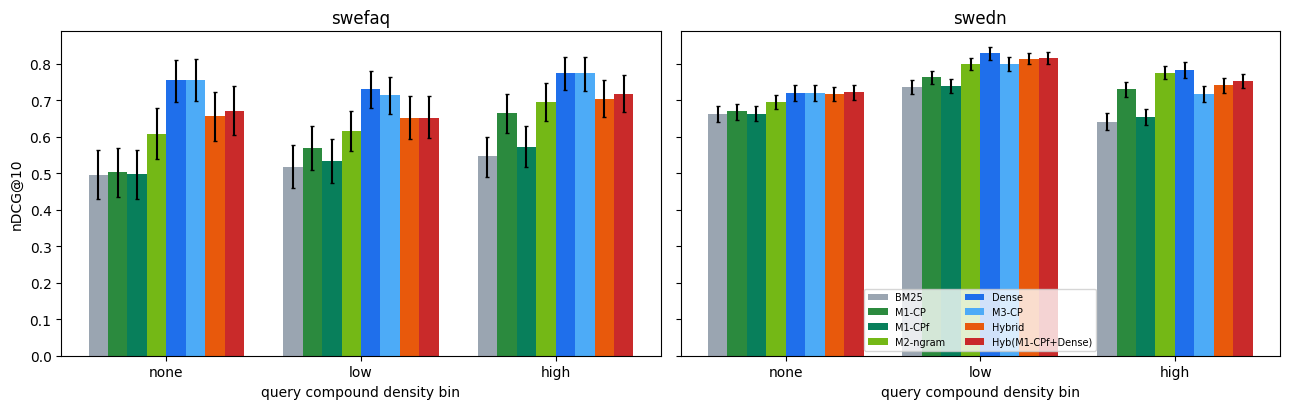

In [18]:
import matplotlib.pyplot as plt
show = ["BM25", "M1-CP", "M1-CPf", "M2-ngram", "Dense", "M3-CP", "Hybrid", "Hyb(M1-CPf+Dense)"]
cols_ = ["#9aa5b1", "#2b8a3e", "#087f5b", "#74b816", "#1f6feb", "#4dabf7", "#e8590c", "#c92a2a"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, ds in zip(axes, DS):
    bins = ["0_none", "1_low", "2_high"]; x = np.arange(3); w = 0.8 / len(show)
    for i, (m, c) in enumerate(zip(show, cols_)):
        vals = [long[(long.ds == ds) & (long.method == m) & (long.q_bin == b)].ndcg10 for b in bins]
        ax.bar(x + (i - len(show) / 2 + .5) * w, [v.mean() for v in vals], w, color=c, label=m,
               yerr=[[v.mean() - boot_ci(v)[0] for v in vals], [boot_ci(v)[1] - v.mean() for v in vals]], capsize=1.5)
    ax.set_xticks(x); ax.set_xticklabels([b[2:] for b in bins]); ax.set_title(ds); ax.set_xlabel("query compound density bin")
axes[0].set_ylabel("nDCG@10"); axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(os.path.join(RES_DIR, "step5_methods_by_density.png"), dpi=200); plt.show()

## Save
`results/`: `step5_perquery.jsonl`, `step5_overall_ndcg10.csv`, `step5_bins_ndcg10.csv`, `step5_paired_diff_by_bin.csv`, `step5_rescued_hurt.csv`, `step5_significance.csv`, `step5_methods_by_density.png`.
**"Save & Run All"** koro (cp_cache.json-e notun shobd jog hoyeche, oita-o save thakbe). Tarpor overall table, bin table, rescued table ar sig table amake pathao.